# 34 — Final FedReTrust research results

Final project candidate: **v0.6**, with v0.5 retained as an earlier-version comparison.
This notebook reads completed, frozen evidence only. No training or checkpoint evaluation.
The corpus has 880 distinct runs, 14 method identifiers and five paired blocks per measured cell.
The main comparison excludes three v0.3 component controls. IID and non-IID remain separate.

All intervals are nominal 95% t intervals across five known development blocks (df4).
They are exploratory, may be unstable at n=5, and have no simultaneous coverage.
The version selection used known block results; this is not untouched confirmation.


In [1]:
from pathlib import Path
import json, hashlib
import pandas as pd
from IPython.display import display, Image, Markdown
HERE = Path.cwd()
EXP = next((p for p in [HERE, *HERE.parents] if (p/'outputs/final_results/20261031_v06').is_dir()), None)
if EXP is None:
    candidate = HERE/'Experiment'
    EXP = candidate if (candidate/'outputs/final_results/20261031_v06').is_dir() else Path('./Experiment')
PACKAGE = EXP/'outputs/final_results/20261031_v06'
assert PACKAGE.is_dir()
CORE = pd.read_csv(PACKAGE/'tables/core_results.csv')
PAIRS = pd.read_csv(PACKAGE/'tables/paired_effects.csv')
ORDER = ['FedAvg', 'RFA', 'FLTrust', 'Viceroy', 'FedReTrust-Direction-loose', 'FedReTrust-v05', 'FedReTrust-v06', 'FLAURA-reconstruction', 'FLAURA-sigma-double', 'FedCognis-aggregation', 'FedCognis-squared-distance']
LABELS = {'FedAvg': 'FedAvg', 'RFA': 'RFA', 'FLTrust': 'FLTrust', 'Viceroy': 'Viceroy', 'FedReTrust-Direction-loose': 'FedReTrust v0.3', 'FedReTrust-v05': 'FedReTrust v0.5', 'FedReTrust-v06': 'FedReTrust v0.6', 'FLAURA-reconstruction': 'FLAURA reconstruction', 'FLAURA-sigma-double': 'FLAURA double sigma', 'FedCognis-aggregation': 'FedCognis aggregation', 'FedCognis-squared-distance': 'FedCognis squared distance'}
print('Selected method: FedReTrust v0.6. Evidence: 880 distinct trajectories; 73 frozen scientific sources.')
print('Main outcomes use rounds 5–24 of 24. Five blocks are repetitions, not extra rounds.')
assert CORE[CORE.status.eq('measured')].n.eq(5).all()
assert CORE[CORE.status.eq('not_tested')]['mean'].isna().all()


Selected method: FedReTrust v0.6. Evidence: 880 distinct trajectories; 73 frozen scientific sources.
Main outcomes use rounds 5–24 of 24. Five blocks are repetitions, not extra rounds.


## Main results

Clean and attacked accuracy use all clients' legitimate tasks. Honest noise and stripes
use the affected honest clients' tasks. Damage is each method's matched clean accuracy
minus attacked accuracy, in percentage points. Absolute attacked accuracy is shown alongside it.
FLAURA/FedCognis noise cells are untested. They are never filled using earlier two-seed results.


### IID

measurement,Attacked accuracy (%),Clean accuracy (%),Honest noise accuracy (%),Honest stripe accuracy (%),Label-flip damage (pp)
method,,,,,
FedAvg,71.958,88.657,88.173,82.216,16.699
RFA,88.139,88.641,88.194,70.802,0.501
FLTrust,88.146,88.355,87.848,58.401,0.209
Viceroy,85.263,88.615,88.153,80.053,3.352
FedReTrust v0.3,87.924,88.636,88.169,82.045,0.712
FedReTrust v0.5,88.023,88.636,88.169,82.041,0.613
FedReTrust v0.6,88.009,88.636,88.169,80.923,0.627
FLAURA reconstruction,85.690,88.648,Not tested,58.327,2.958
FLAURA double sigma,87.867,88.664,Not tested,62.839,0.797


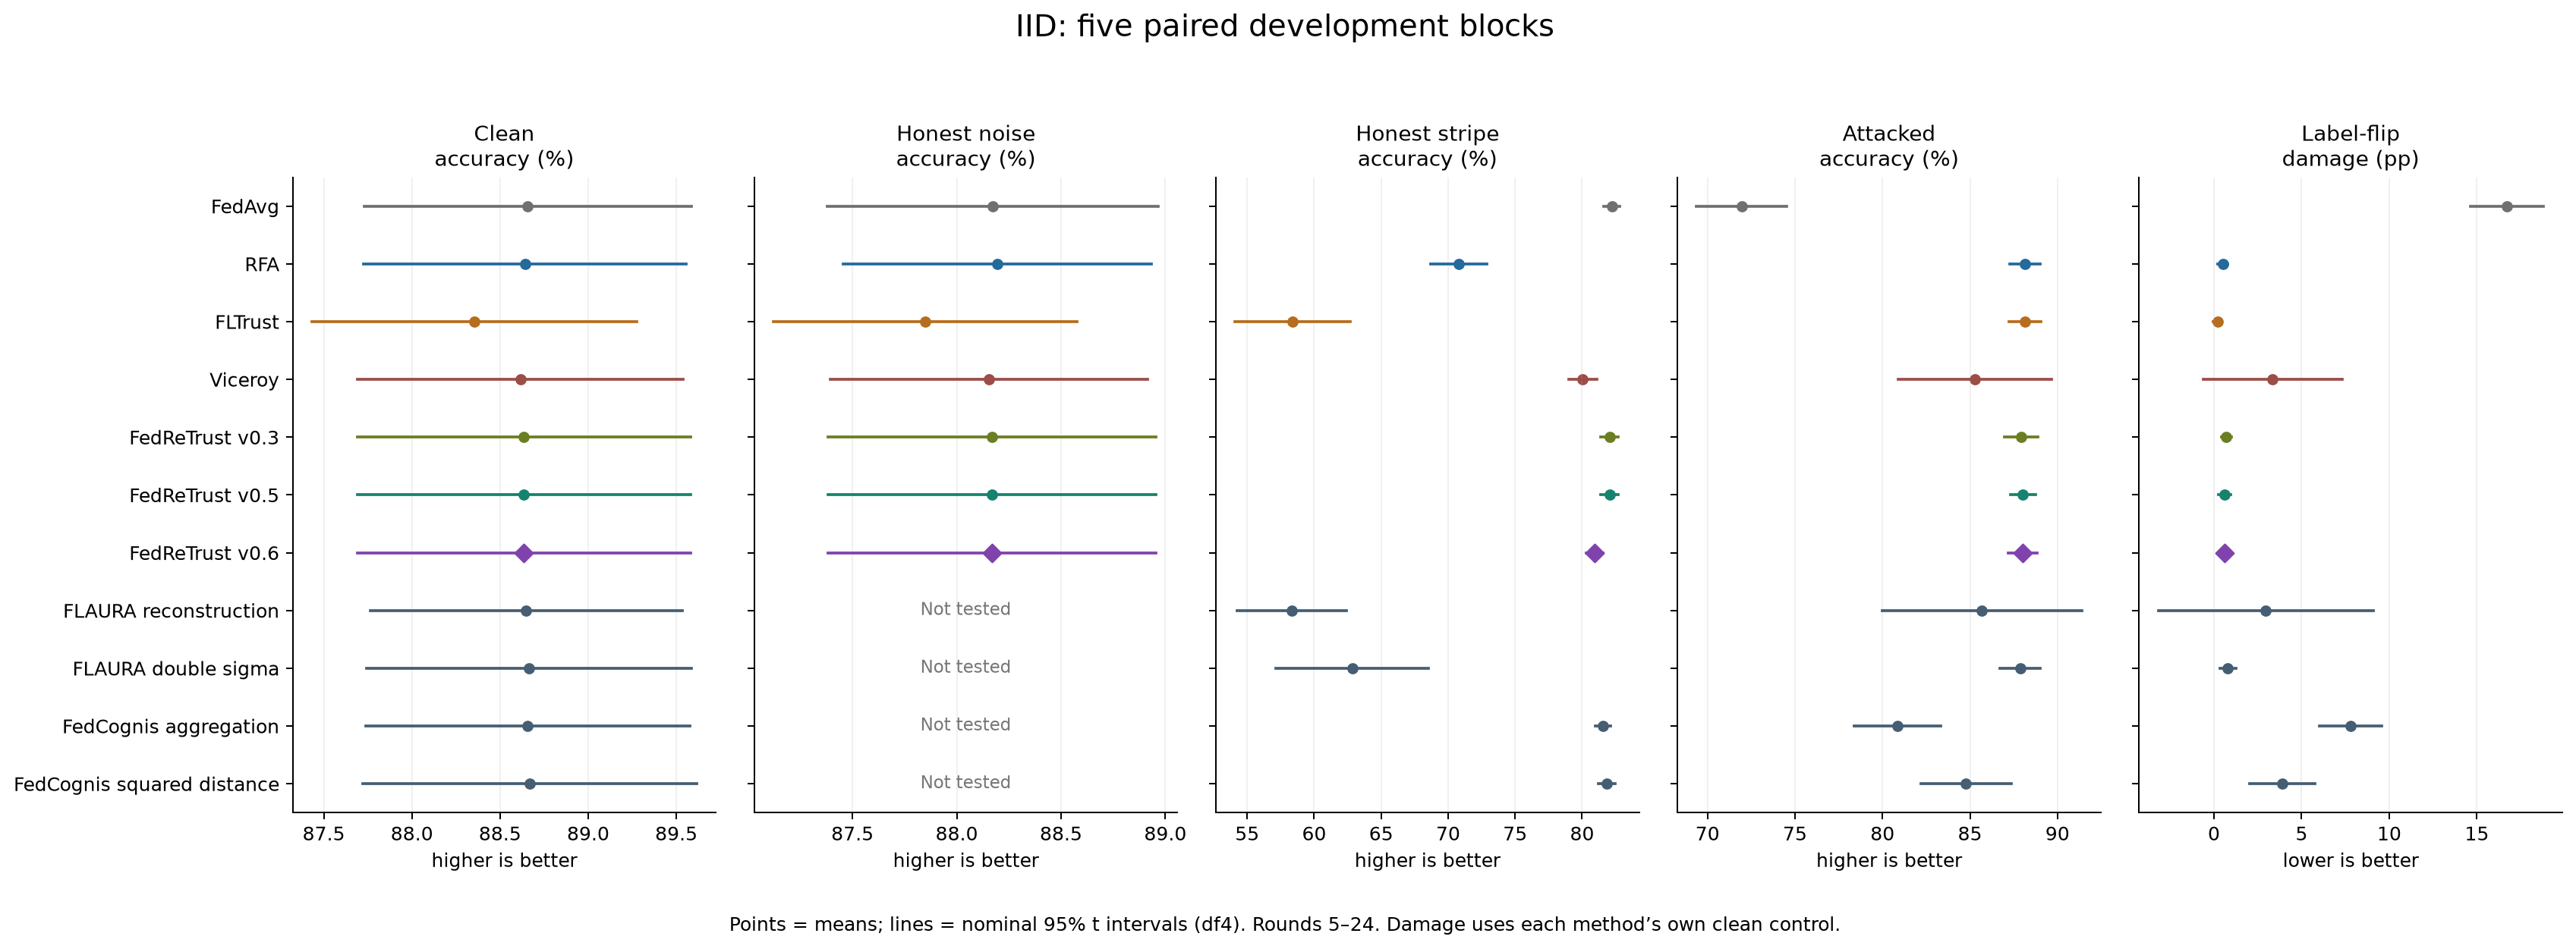

### non-IID

measurement,Attacked accuracy (%),Clean accuracy (%),Honest noise accuracy (%),Honest stripe accuracy (%),Label-flip damage (pp)
method,,,,,
FedAvg,66.903,85.387,82.942,80.593,18.485
RFA,81.287,85.945,82.809,77.473,4.658
FLTrust,78.712,81.773,77.934,47.267,3.062
Viceroy,51.668,79.989,79.529,70.547,28.320
FedReTrust v0.3,76.031,84.509,81.496,80.320,8.478
FedReTrust v0.5,77.349,84.732,81.816,80.311,7.384
FedReTrust v0.6,79.198,84.813,81.902,80.813,5.615
FLAURA reconstruction,71.351,82.952,Not tested,75.999,11.601
FLAURA double sigma,76.799,85.068,Not tested,76.091,8.269


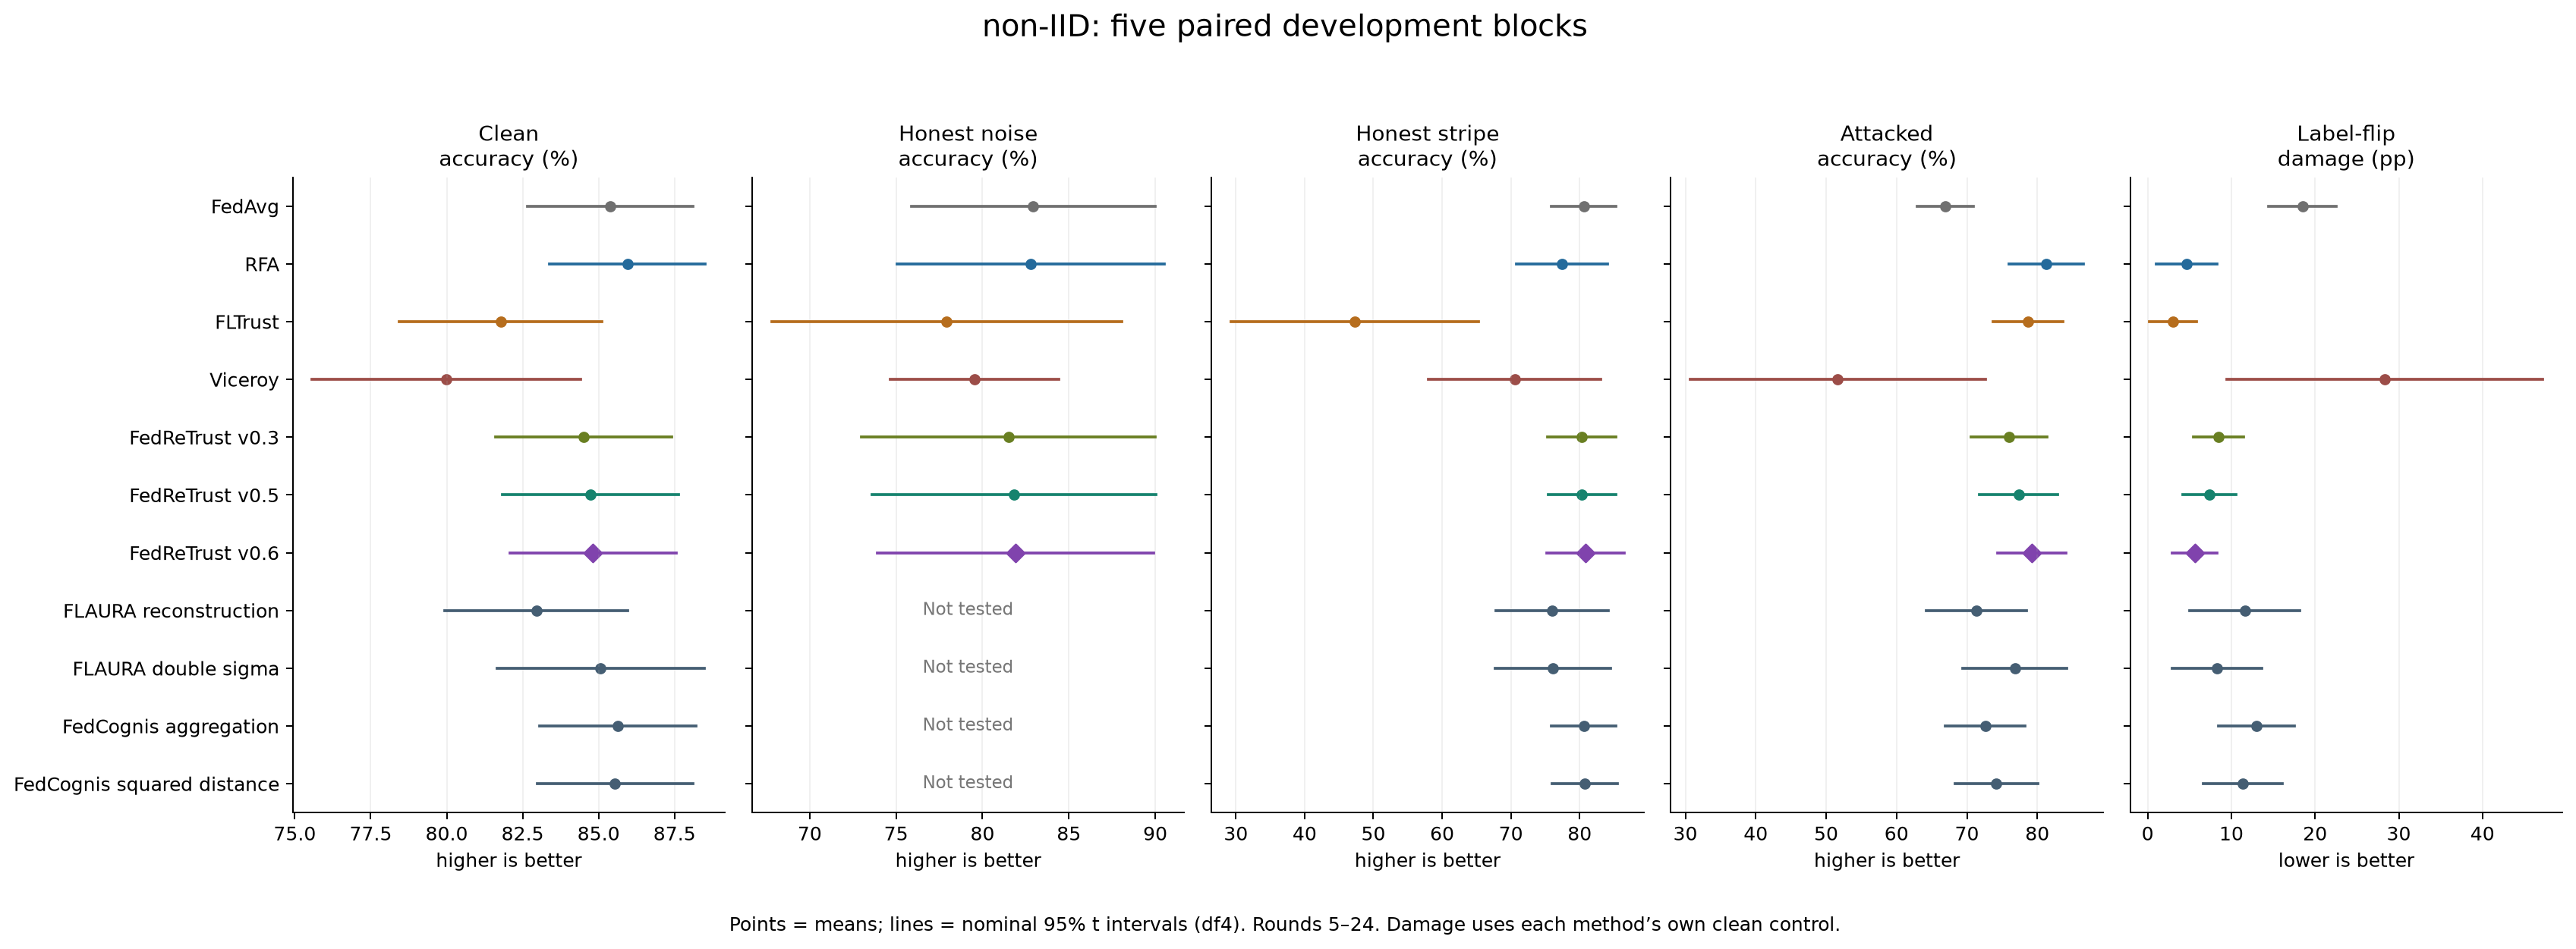

In [2]:
for regime in ['IID', 'non-IID']:
    display(Markdown('### '+regime))
    table = CORE[CORE.regime.eq(regime)].pivot(index='method', columns='measurement', values='mean')
    display(table.reindex(ORDER).rename(index=LABELS).round(3).fillna('Not tested'))
    display(Image(filename=str(PACKAGE/'figures'/('core_'+regime.replace('-','_')+'.png'))))


## The selected compromise

v0.6 reduces non-IID label-flip damage relative to v0.5 in all five blocks, with a
mean reduction of 1.7684 pp (nominal paired interval 0.6225–2.9142). IID stripe
accuracy falls by 1.1176 pp (loss interval 0.0148–2.2203). RFA retains better mean
non-IID attack protection; v0.6 retains better stripe accuracy. No scalar balance
score or universal ranking was predeclared.


,regime,comparator,scenario,metric,block_1,block_2,block_3,block_4,block_5,mean,ci_low,ci_high
0,IID,FedAvg,abrupt_shot_noise,affected_honest_event_pp,-0.010,0.001,0.008,0.005,-0.024,-0.004,-0.020,0.013
1,IID,FedAvg,clean,overall_mean_5_24_pp,-0.021,-0.019,-0.052,-0.010,-0.004,-0.021,-0.044,0.002
2,IID,FedAvg,gradual_stripe,affected_honest_event_pp,-2.133,-2.128,0.052,-1.348,-0.908,-1.293,-2.432,-0.155
3,IID,FedAvg,label_flip,attack_active_signed_damage_pp,-14.492,-14.122,-18.378,-16.267,-17.099,-16.072,-18.285,-13.858
4,IID,FedAvg,label_flip,overall_mean_5_24_pp,14.471,14.104,18.326,16.257,17.095,16.051,13.847,18.254
5,non-IID,FedAvg,abrupt_shot_noise,affected_honest_event_pp,-0.858,-1.673,-2.460,-0.222,0.013,-1.040,-2.317,0.237
6,non-IID,FedAvg,clean,overall_mean_5_24_pp,-0.988,-0.776,-0.841,-0.126,-0.141,-0.574,-1.083,-0.066
7,non-IID,FedAvg,gradual_stripe,affected_honest_event_pp,1.364,0.414,-1.371,0.413,0.280,0.220,-1.009,1.449
8,non-IID,FedAvg,label_flip,attack_active_signed_damage_pp,-14.003,-10.899,-10.324,-10.941,-18.179,-12.869,-16.967,-8.772
9,non-IID,FedAvg,label_flip,overall_mean_5_24_pp,13.016,10.123,9.484,10.815,18.038,12.295,7.980,16.611


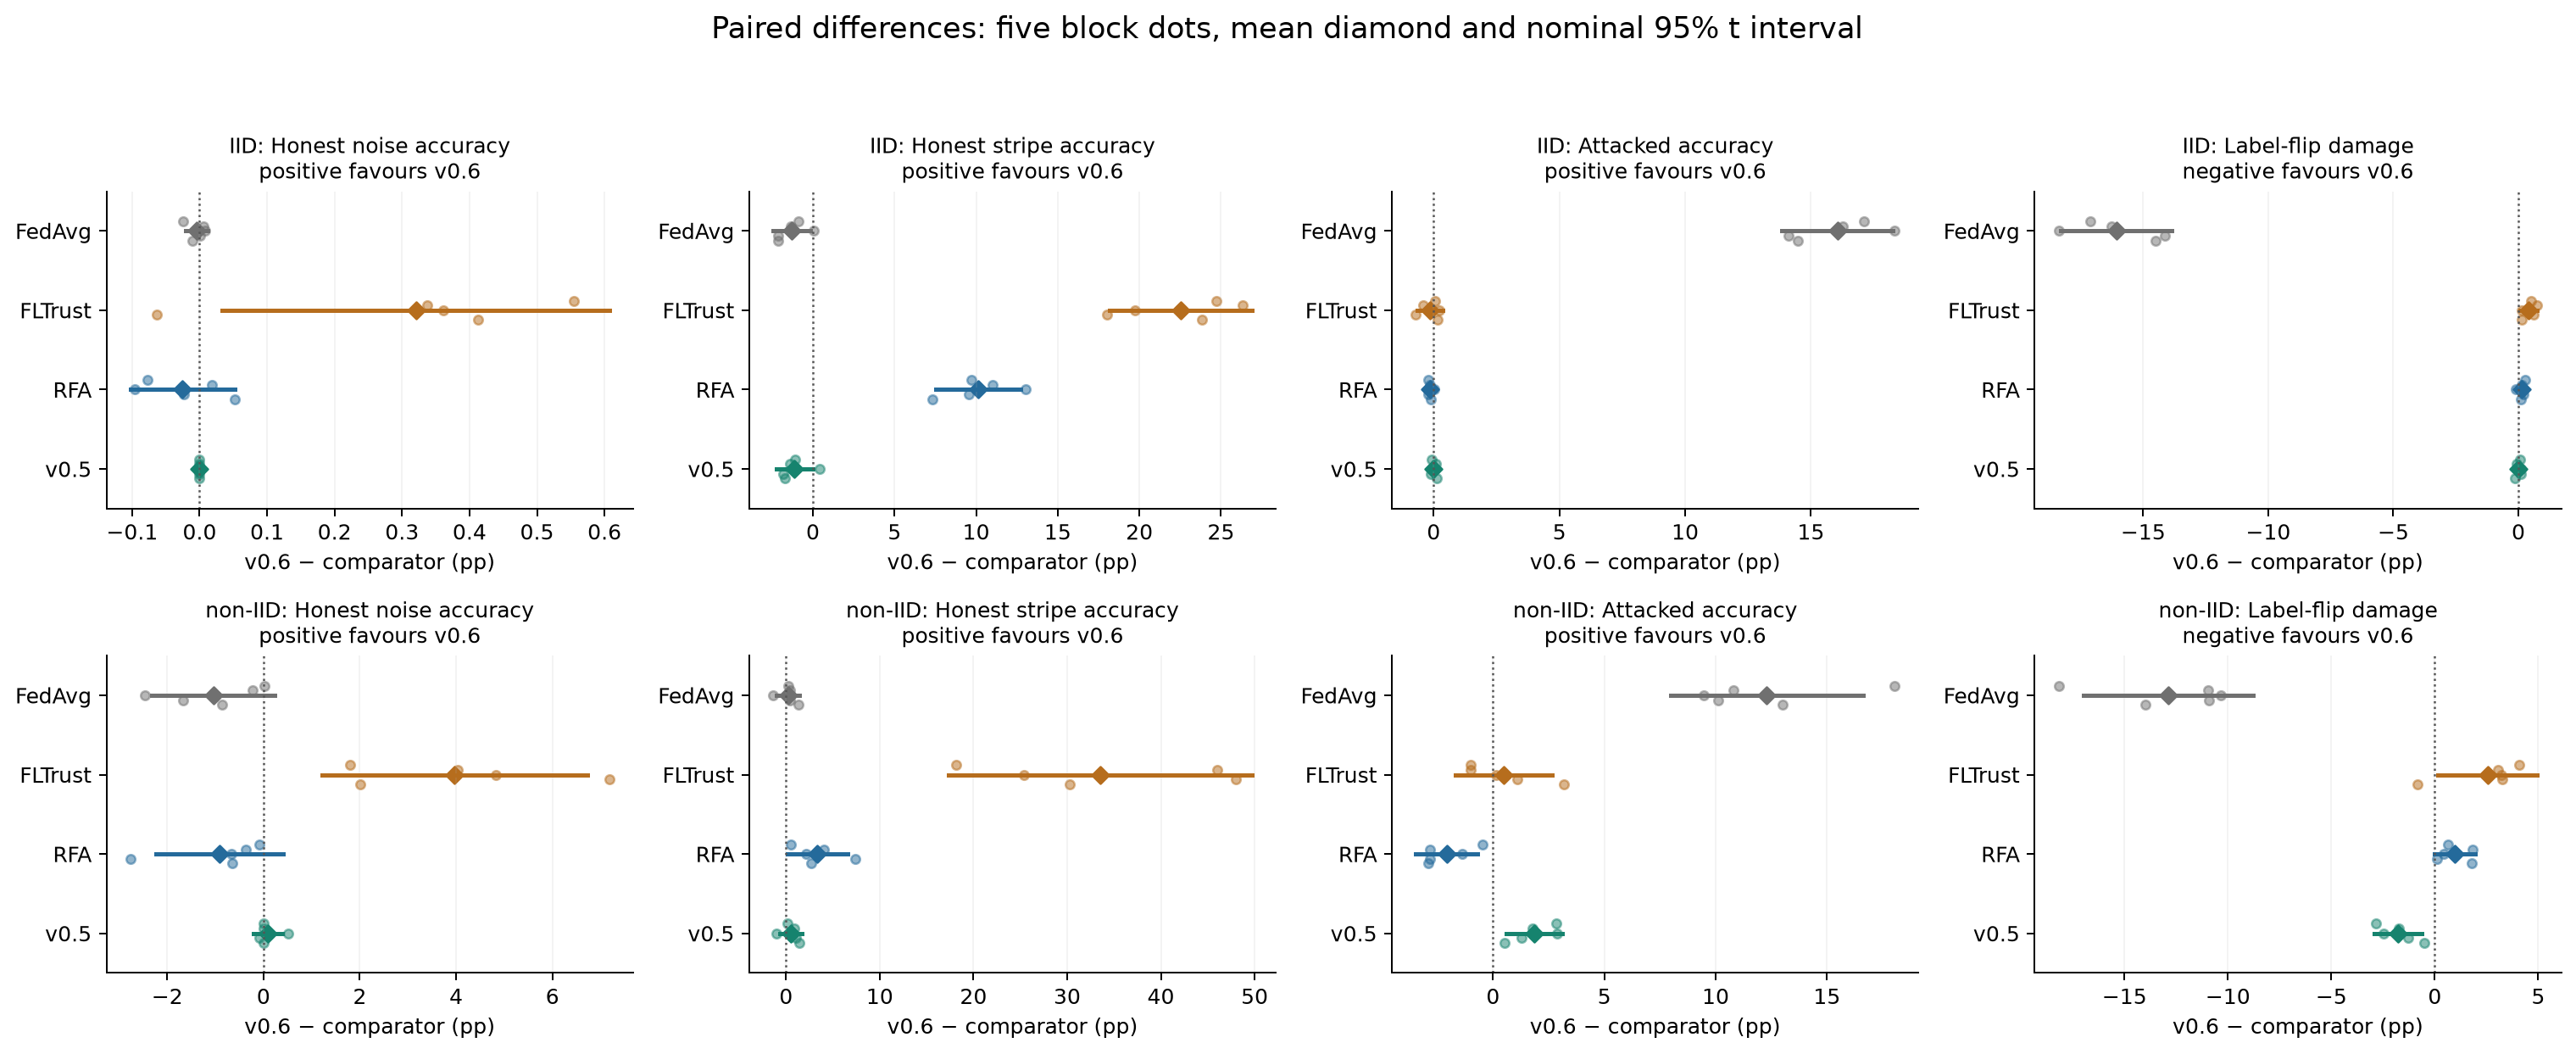

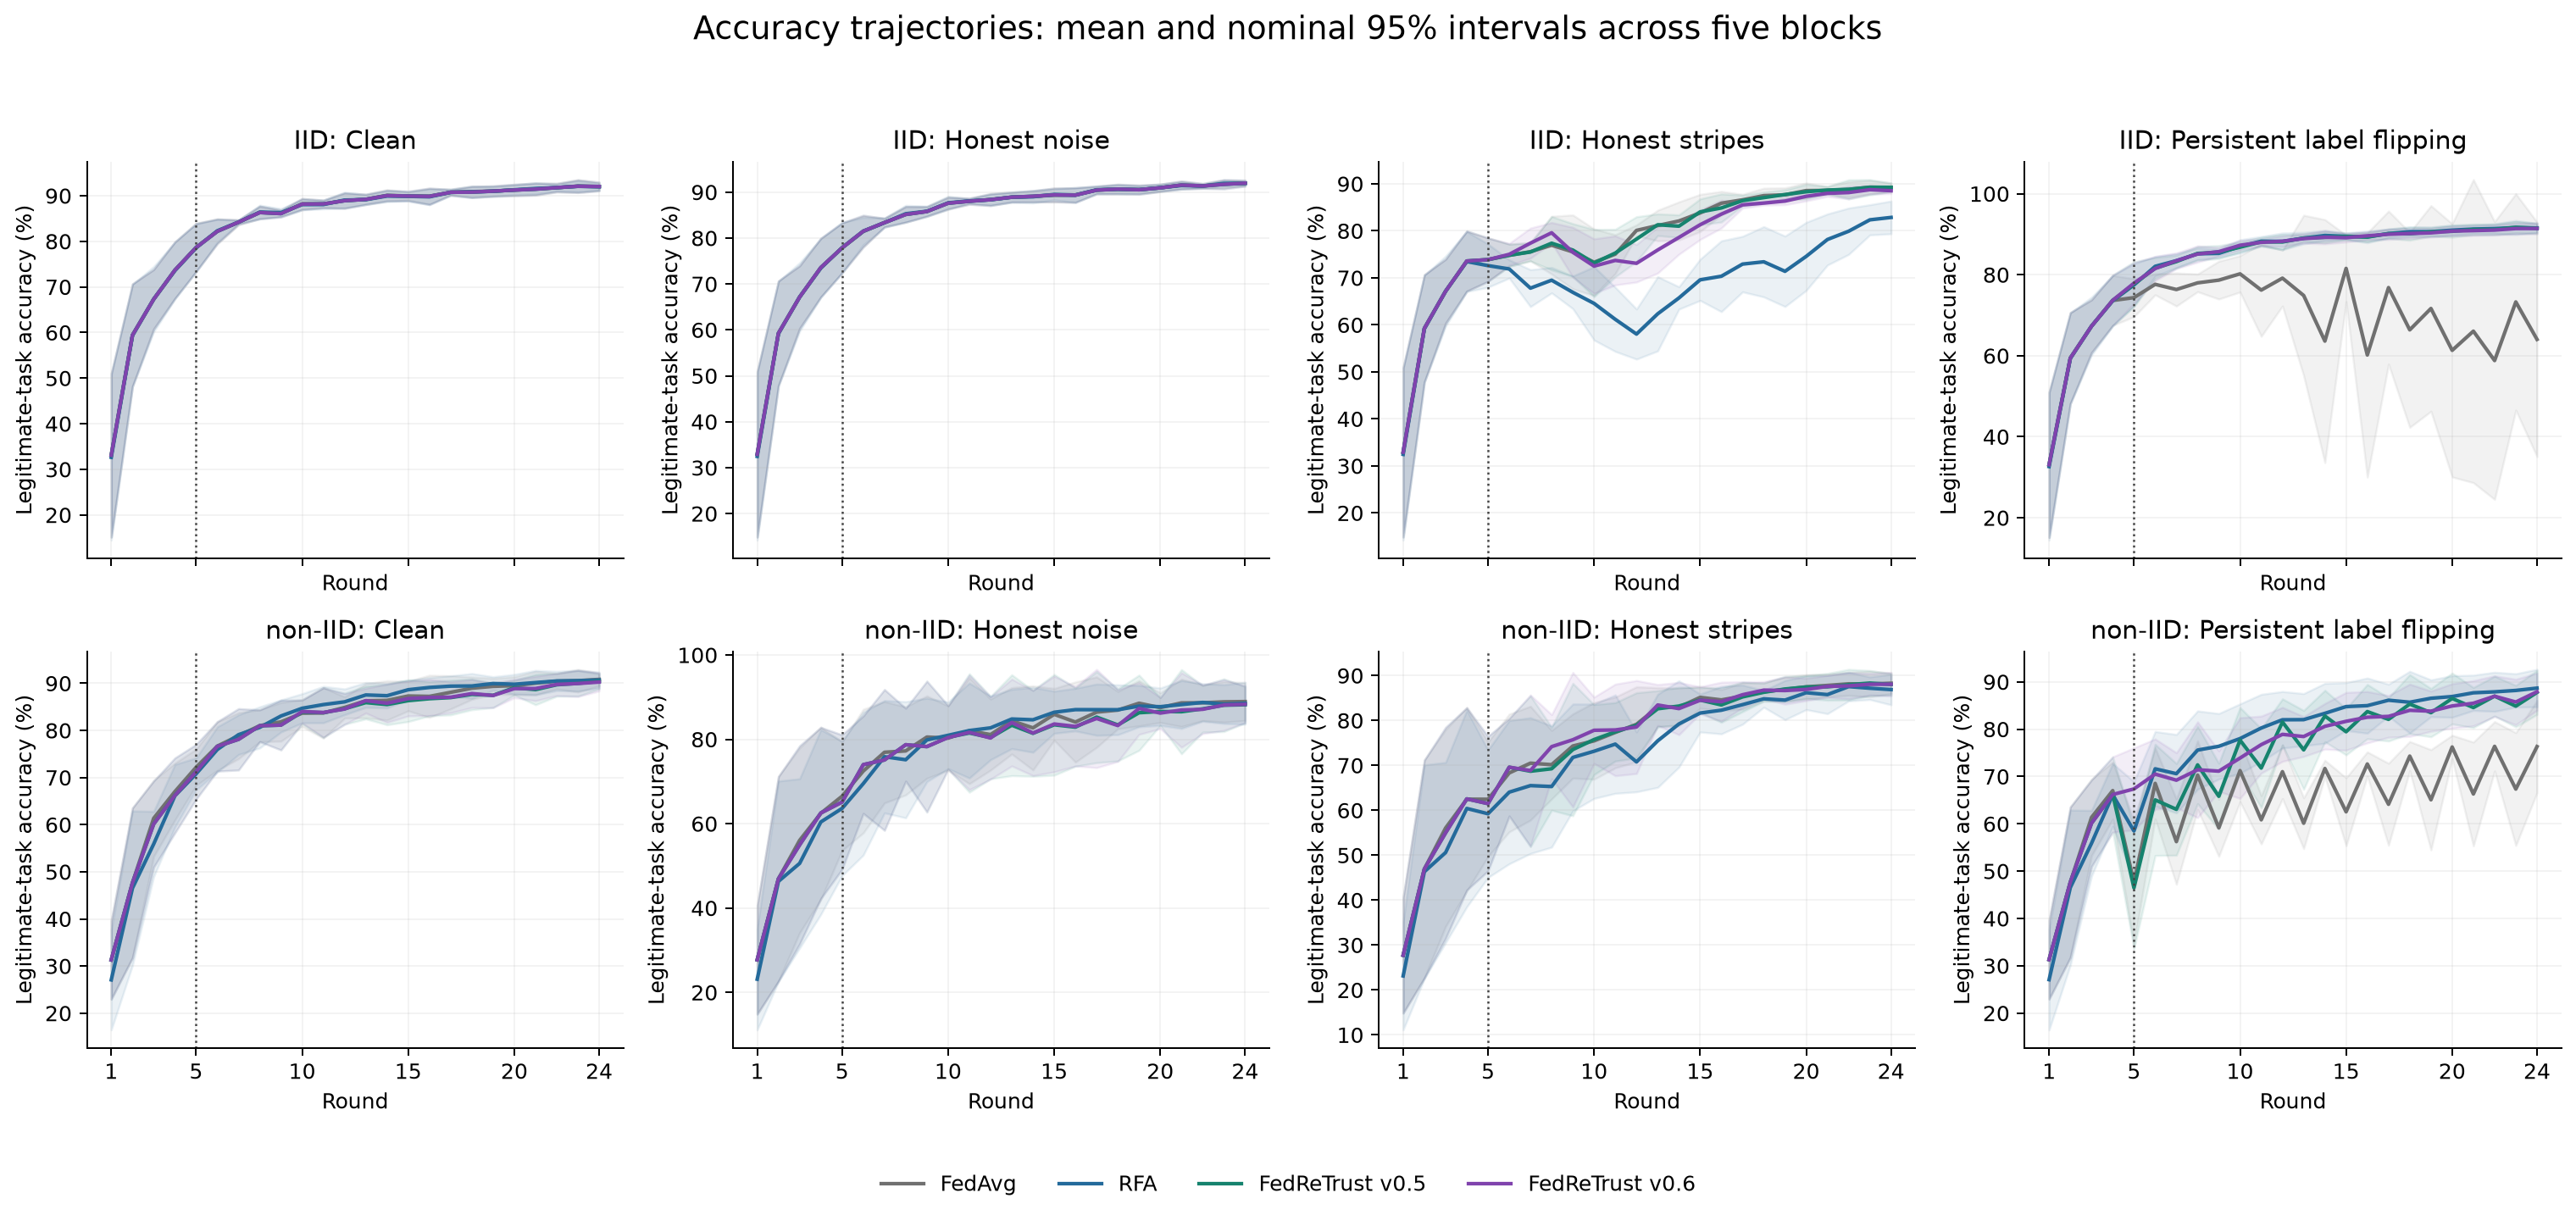

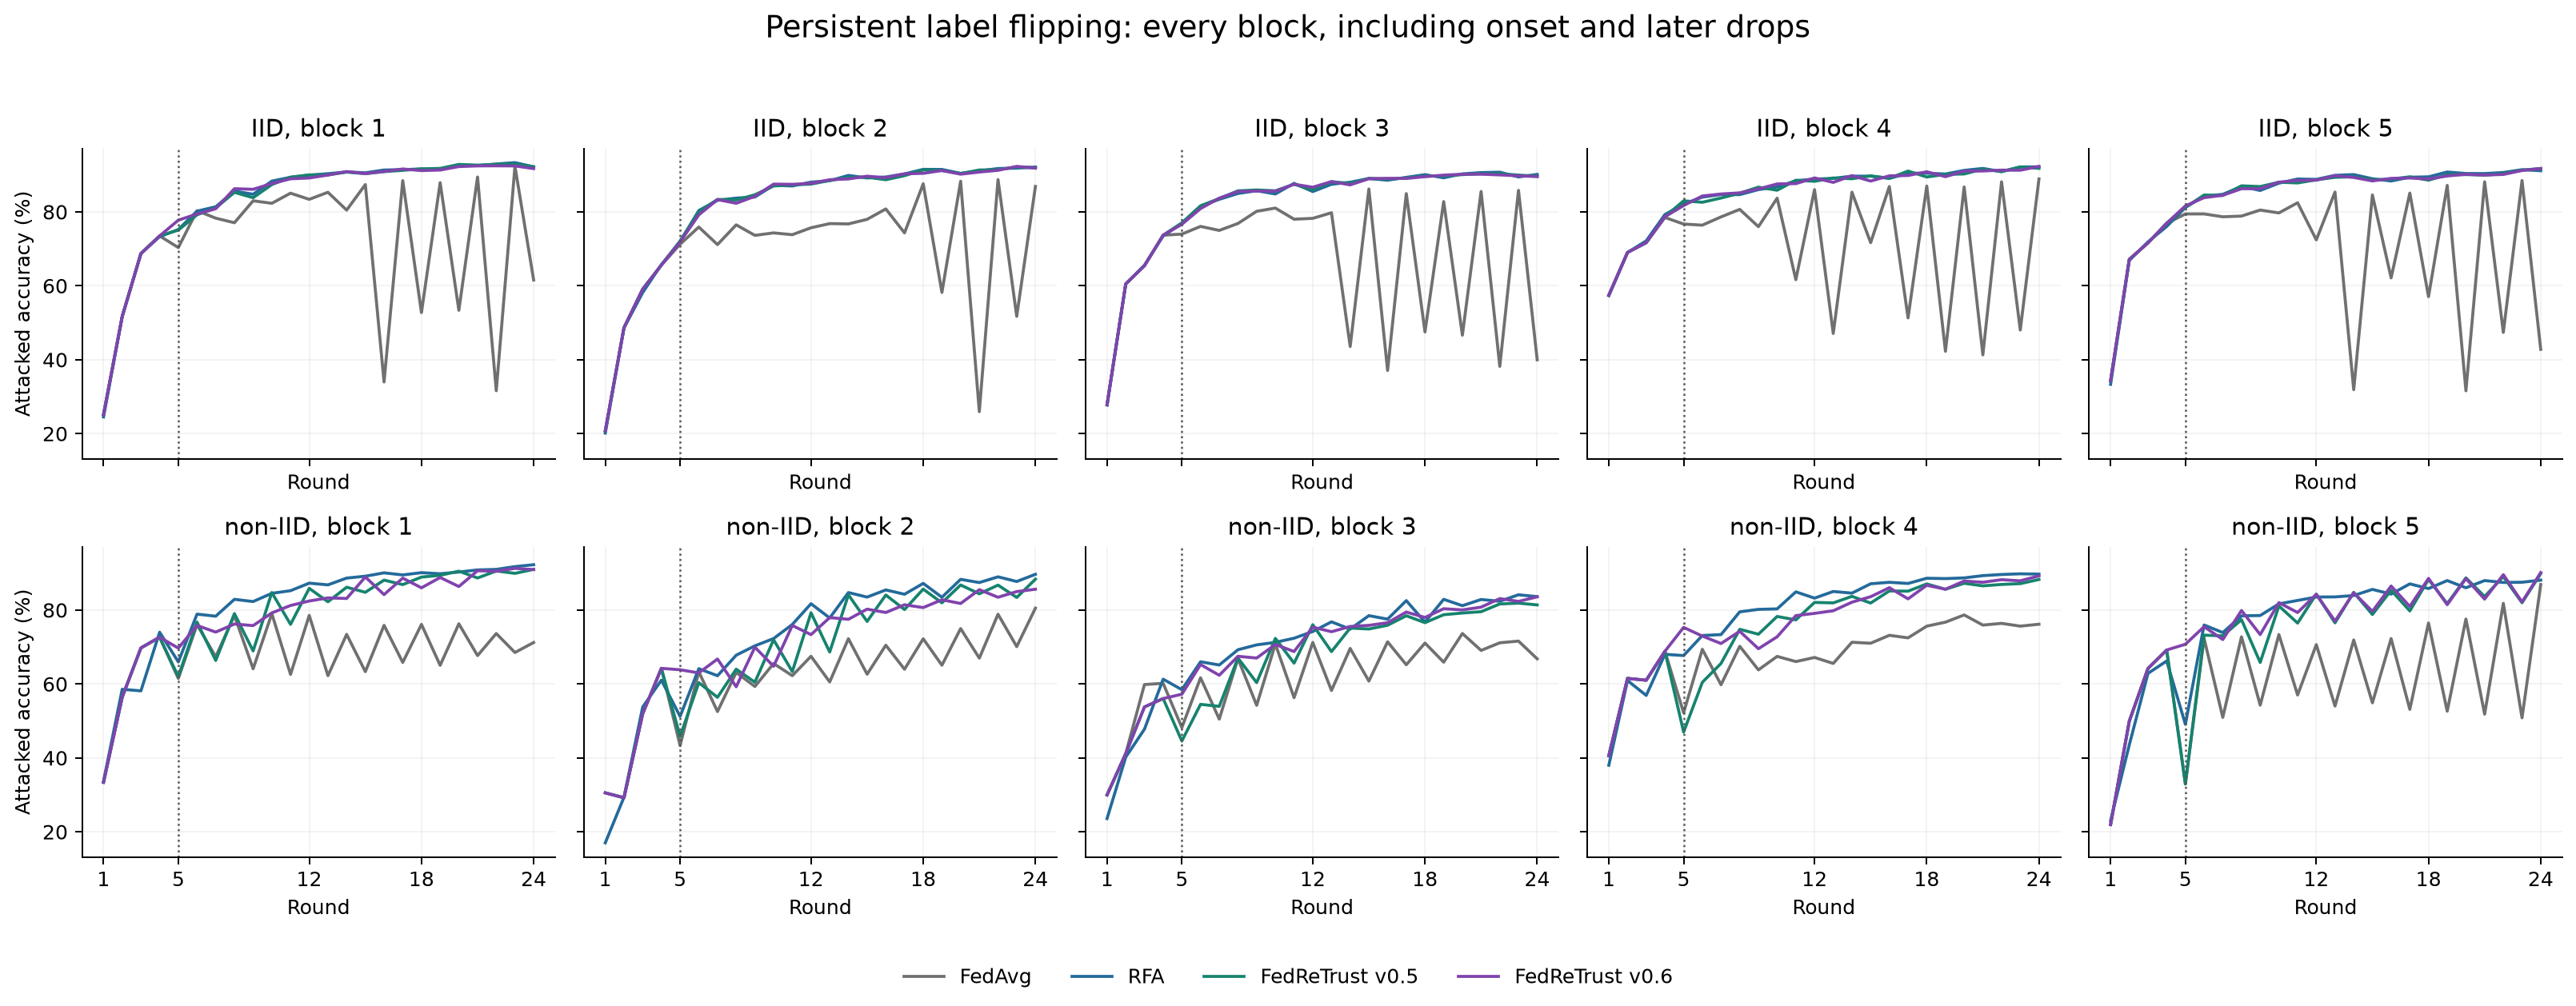

In [3]:
keep = PAIRS.candidate.eq('FedReTrust-v06') & PAIRS.comparator.isin(['FedReTrust-v05','RFA','FLTrust','FedAvg'])
spec = CORE[['scenario','metric']].drop_duplicates()
view = PAIRS[keep].merge(spec,on=['scenario','metric'])
display(view[['regime','comparator','scenario','metric','block_1','block_2','block_3','block_4','block_5','mean','ci_low','ci_high']].round(3))
display(Image(filename=str(PACKAGE/'figures/paired_v06.png')))
display(Image(filename=str(PACKAGE/'figures/core_trajectories.png')))
display(Image(filename=str(PACKAGE/'figures/label_flip_blocks.png')))


## Targets and coverage limits

45/51 unchanged follow-up checks pass: original practical 8/10, IID retention 21/25,
non-IID focus 16/16. The pilot remains failed. These are engineering margins,
not statistical proof of superiority. v0.6 has no five-block attack-stop, recurring,
mixed-event or Gaussian-update result. Historical component controls concern v0.3 only.


In [4]:
G = pd.read_csv(PACKAGE/'tables/v06_followup_gates.csv')
assert len(G)==51 and int(G.point_pass.sum())==45
display(G.groupby('gate_group').point_pass.agg(['sum','count']))
display(pd.read_csv(PACKAGE/'tables/v06_failed_targets.csv')[['gate_group','regime','scenario','gate_block','criterion','checked_difference_pp','bound_pp','direction']])
display(pd.read_csv(PACKAGE/'tables/methods_and_access.csv'))
coverage = pd.read_csv(PACKAGE/'tables/coverage.csv')
display(coverage[coverage.regime.eq('IID')].pivot(index='method',columns='scenario',values='status'))
print('Recovery: within 1 pp of matched control for three consecutive eligible post-attack rounds; censored outcomes remain censored.')
display(pd.read_csv(PACKAGE/'tables/recovery_counts.csv'))
display(pd.read_csv(PACKAGE/'tables/v03_component_contrasts.csv').round(3))


Recovery: within 1 pp of matched control for three consecutive eligible post-attack rounds; censored outcomes remain censored.


,sum,count
gate_group,,
IID_retention,21,25
nonIID_focus,16,16
original_practical_target,8,10


,gate_group,regime,scenario,gate_block,criterion,checked_difference_pp,bound_pp,direction
0,original_practical_target,IID,gradual_stripe,NaN,honest_accuracy_within_1pp_FedAvg,-1.293128,-1.0,>=
1,original_practical_target,non-IID,abrupt_shot_noise,NaN,honest_accuracy_within_1pp_FedAvg,-1.039965,-1.0,>=
2,IID_retention,IID,gradual_stripe,1.0,IID_accuracy_within_half_pp_v05,-1.704630,-0.5,>=
3,IID_retention,IID,gradual_stripe,2.0,IID_accuracy_within_half_pp_v05,-1.797327,-0.5,>=
4,IID_retention,IID,gradual_stripe,4.0,IID_accuracy_within_half_pp_v05,-1.384057,-0.5,>=
5,IID_retention,IID,gradual_stripe,5.0,IID_accuracy_within_half_pp_v05,-1.093123,-0.5,>=


,method,display_name,runs,server_reference_images,reference_role,implementation_scope,official_test_used,defence_uses_evaluation_data
0,FLAURA-reconstruction,FLAURA reconstruction,30,100,100 auxiliary images plus earlier frozen calib...,documented reconstruction/sensitivity variant;...,False,False
1,FLAURA-sigma-double,FLAURA double sigma,30,100,100 auxiliary images plus earlier frozen calib...,documented reconstruction/sensitivity variant;...,False,False
2,FLTrust,FLTrust,100,300,300 clean root-training images,frozen project implementation,False,False
3,FedAvg,FedAvg,100,0,no server reference images,frozen project implementation,False,False
4,FedCognis-aggregation,FedCognis aggregation,30,0,no server reference images,documented reconstruction/sensitivity variant;...,False,False
5,FedCognis-squared-distance,FedCognis squared distance,30,0,no server reference images,documented reconstruction/sensitivity variant;...,False,False
6,FedReTrust-Direction-loose,FedReTrust v0.3,100,0,no server reference images,frozen project implementation,False,False
7,FedReTrust-v03-capped-RFA,FedReTrust-v03-capped-RFA,60,0,no server reference images,v0.3-only component control,False,False
8,FedReTrust-v03-no-clipping,FedReTrust-v03-no-clipping,60,0,no server reference images,v0.3-only component control,False,False
9,FedReTrust-v03-no-restoration,FedReTrust-v03-no-restoration,60,0,no server reference images,v0.3-only component control,False,False


scenario,abrupt_shot_noise,attack_stops,clean,gaussian_update,gradual_stripe,honest_change_stops,label_flip,mixed_drift_and_attack,mixed_drift_only_control,recurring_attack
method,,,,,,,,,,
FLAURA-reconstruction,not_tested,not_tested,measured_five_blocks,not_tested,measured_five_blocks,not_tested,measured_five_blocks,not_tested,not_tested,not_tested
FLAURA-sigma-double,not_tested,not_tested,measured_five_blocks,not_tested,measured_five_blocks,not_tested,measured_five_blocks,not_tested,not_tested,not_tested
FLTrust,measured_five_blocks,measured_five_blocks,measured_five_blocks,measured_five_blocks,measured_five_blocks,measured_five_blocks,measured_five_blocks,measured_five_blocks,measured_five_blocks,measured_five_blocks
FedAvg,measured_five_blocks,measured_five_blocks,measured_five_blocks,measured_five_blocks,measured_five_blocks,measured_five_blocks,measured_five_blocks,measured_five_blocks,measured_five_blocks,measured_five_blocks
FedCognis-aggregation,not_tested,not_tested,measured_five_blocks,not_tested,measured_five_blocks,not_tested,measured_five_blocks,not_tested,not_tested,not_tested
FedCognis-squared-distance,not_tested,not_tested,measured_five_blocks,not_tested,measured_five_blocks,not_tested,measured_five_blocks,not_tested,not_tested,not_tested
FedReTrust-Direction-loose,measured_five_blocks,measured_five_blocks,measured_five_blocks,measured_five_blocks,measured_five_blocks,measured_five_blocks,measured_five_blocks,measured_five_blocks,measured_five_blocks,measured_five_blocks
FedReTrust-v03-capped-RFA,not_tested,measured_five_blocks,measured_five_blocks,not_tested,measured_five_blocks,measured_five_blocks,measured_five_blocks,not_tested,not_tested,measured_five_blocks
FedReTrust-v03-no-clipping,not_tested,measured_five_blocks,measured_five_blocks,not_tested,measured_five_blocks,measured_five_blocks,measured_five_blocks,not_tested,not_tested,measured_five_blocks


,method,regime,scenario,group,episode,blocks,confirmed,censored,already_within_at_attack_end,later_relapse
0,FLTrust,IID,attack_stops,affected_attackers,1,5,5,0,5,0
1,FLTrust,IID,attack_stops,all_clients,1,5,5,0,5,0
2,FLTrust,IID,mixed_drift_and_attack,affected_attackers,1,5,5,0,5,1
3,FLTrust,IID,mixed_drift_and_attack,all_clients,1,5,5,0,4,1
4,FLTrust,IID,recurring_attack,affected_attackers,1,5,4,1,2,0
...,...,...,...,...,...,...,...,...,...,...
111,Viceroy,non-IID,mixed_drift_and_attack,all_clients,1,5,3,2,0,0
112,Viceroy,non-IID,recurring_attack,affected_attackers,1,5,1,4,0,0
113,Viceroy,non-IID,recurring_attack,affected_attackers,2,5,0,5,0,0
114,Viceroy,non-IID,recurring_attack,all_clients,1,5,1,4,0,0


,target,comparator,regime,scenario,metric,blocks,paired_differences_pp,n,expected_n,complete_seed_coverage,mean,sd,ci_low,ci_high
0,FedReTrust-Direction-loose,FedReTrust-v03-capped-RFA,IID,attack_stops,attack_tail_damage_21_24_pp,"[1, 2, 3, 4, 5]","[-0.1286638733705825, -0.05509776536313238, 0....",5,5,True,-0.003,0.088,-0.112,0.106
1,FedReTrust-Direction-loose,FedReTrust-v03-capped-RFA,IID,clean,overall_mean_5_24_pp,"[1, 2, 3, 4, 5]","[-0.015745810055861398, -0.0043677839851170575...",5,5,True,-0.005,0.058,-0.077,0.068
2,FedReTrust-Direction-loose,FedReTrust-v03-capped-RFA,IID,gradual_stripe,affected_honest_event_pp,"[1, 2, 3, 4, 5]","[11.628708488516452, 11.48655027932962, 12.634...",5,5,True,12.584,1.491,10.733,14.435
3,FedReTrust-Direction-loose,FedReTrust-v03-capped-RFA,IID,honest_change_stops,affected_honest_return_11_24_pp,"[1, 2, 3, 4, 5]","[0.04378380775028745, -0.015646891903898563, -...",5,5,True,0.027,0.057,-0.043,0.098
4,FedReTrust-Direction-loose,FedReTrust-v03-capped-RFA,IID,label_flip,attack_active_signed_damage_pp,"[1, 2, 3, 4, 5]","[0.2727560521415283, 0.1598407821229092, 0.309...",5,5,True,0.215,0.084,0.110,0.320
5,FedReTrust-Direction-loose,FedReTrust-v03-capped-RFA,IID,recurring_attack,second_attack_signed_damage_pp,"[1, 2, 3, 4, 5]","[0.31753258845438614, 0.5958379888268306, 1.35...",5,5,True,0.910,0.440,0.364,1.456
6,FedReTrust-Direction-loose,FedReTrust-v03-capped-RFA,non-IID,attack_stops,attack_tail_damage_21_24_pp,"[1, 2, 3, 4, 5]","[-0.5132076350093162, -1.4404236499069079, 0.0...",5,5,True,-0.184,0.830,-1.215,0.847
7,FedReTrust-Direction-loose,FedReTrust-v03-capped-RFA,non-IID,clean,overall_mean_5_24_pp,"[1, 2, 3, 4, 5]","[-1.4875186219739476, -2.914939478584756, -1.5...",5,5,True,-1.436,1.063,-2.756,-0.116
8,FedReTrust-Direction-loose,FedReTrust-v03-capped-RFA,non-IID,gradual_stripe,affected_honest_event_pp,"[1, 2, 3, 4, 5]","[1.2228317039106287, 6.633123448168831, 3.2341...",5,5,True,2.759,2.430,-0.258,5.777
9,FedReTrust-Direction-loose,FedReTrust-v03-capped-RFA,non-IID,honest_change_stops,affected_honest_return_11_24_pp,"[1, 2, 3, 4, 5]","[-1.2329032544116245, -6.627884189057383, -2.2...",5,5,True,-2.327,2.499,-5.430,0.776


## Training, evaluation and costs

Training loss is online local cross-entropy; local labels can be poisoned. Training
accuracy was not recorded. Fixed balanced task evaluation and population-weighted
legitimate-task evaluation have different denominators. Concurrent timing and
process RSS are descriptive; v0.6 history alone adds 32.17 MiB of tensor payload.
No method reads evaluation scores during aggregation. FLTrust uses 300 clean root
images. FLAURA uses 100 auxiliary images and earlier frozen calibration. v0.6 uses none.


In [5]:
for filename in ['training_loss_summary','evaluation_tasks_cross_entropy_summary','costs_common_three_scenarios']:
    data = pd.read_csv(PACKAGE/'tables'/(filename+'.csv'))
    data = data[data.method.isin(['FedAvg','RFA','FLTrust','FedReTrust-v05','FedReTrust-v06'])]
    if 'scenario' in data: data = data[data.scenario.eq('clean')]
    if 'window' in data: data = data[data.window.eq('primary_5_24')]
    if 'client_group' in data: data = data[data.client_group.eq('all_clients')]
    if 'task' in data: data = data[data.task.eq('clean')]
    if 'resource' in data: data = data[data.resource.isin(['median_defence_seconds','process_lifetime_peak_rss_mib','worker_wall_seconds'])]
    display(Markdown('**'+filename.replace('_',' ')+'**'))
    display(data.round(4))
print('Full tables, definitions, source hashes, original decisions and next-chat handoff are in the results package.')


Full tables, definitions, source hashes, original decisions and next-chat handoff are in the results package.


**training loss summary**

,method,regime,scenario,window,client_group,n,block_1,block_2,block_3,block_4,block_5,mean,sd,min,max,ci_low,ci_high
174,FLTrust,IID,clean,primary_5_24,all_clients,5,0.4228,0.5036,0.4446,0.3884,0.4006,0.4320,0.0454,0.3884,0.5036,0.3756,0.4884
294,FLTrust,non-IID,clean,primary_5_24,all_clients,5,0.5598,0.6908,0.5514,0.4370,0.5028,0.5484,0.0934,0.4370,0.6908,0.4324,0.6643
414,FedAvg,IID,clean,primary_5_24,all_clients,5,0.4398,0.5292,0.4650,0.4089,0.4173,0.4520,0.0483,0.4089,0.5292,0.3920,0.5120
534,FedAvg,non-IID,clean,primary_5_24,all_clients,5,0.4221,0.4589,0.4257,0.3705,0.4033,0.4161,0.0324,0.3705,0.4589,0.3758,0.4564
1458,FedReTrust-v05,IID,clean,primary_5_24,all_clients,5,0.4398,0.5293,0.4650,0.4088,0.4174,0.4521,0.0484,0.4088,0.5293,0.3920,0.5121
1506,FedReTrust-v05,non-IID,clean,primary_5_24,all_clients,5,0.4299,0.4619,0.4397,0.3712,0.4047,0.4215,0.0348,0.3712,0.4619,0.3783,0.4647
1554,FedReTrust-v06,IID,clean,primary_5_24,all_clients,5,0.4398,0.5293,0.4650,0.4088,0.4174,0.4521,0.0484,0.4088,0.5293,0.3920,0.5121
1602,FedReTrust-v06,non-IID,clean,primary_5_24,all_clients,5,0.4299,0.4623,0.4378,0.3709,0.4047,0.4211,0.0348,0.3709,0.4623,0.3780,0.4643
1662,RFA,IID,clean,primary_5_24,all_clients,5,0.4409,0.5299,0.4656,0.4094,0.4183,0.4528,0.0483,0.4094,0.5299,0.3929,0.5128
1782,RFA,non-IID,clean,primary_5_24,all_clients,5,0.4216,0.4476,0.4235,0.3669,0.4101,0.4140,0.0296,0.3669,0.4476,0.3772,0.4507


**evaluation tasks cross entropy summary**

,method,regime,scenario,window,task,n,block_1,block_2,block_3,block_4,block_5,mean,sd,min,max,ci_low,ci_high
216,FLTrust,IID,clean,primary_5_24,clean,5,0.3707,0.4230,0.4200,0.3607,0.4136,0.3976,0.0295,0.3607,0.4230,0.3609,0.4342
366,FLTrust,non-IID,clean,primary_5_24,clean,5,0.5844,0.8010,0.6913,0.5583,0.5825,0.6435,0.1019,0.5583,0.8010,0.5170,0.7701
516,FedAvg,IID,clean,primary_5_24,clean,5,0.3712,0.4351,0.4141,0.3610,0.4070,0.3977,0.0309,0.3610,0.4351,0.3594,0.4360
666,FedAvg,non-IID,clean,primary_5_24,clean,5,0.4283,0.5288,0.5424,0.4905,0.4712,0.4922,0.0458,0.4283,0.5424,0.4354,0.5491
1821,FedReTrust-v05,IID,clean,primary_5_24,clean,5,0.3712,0.4352,0.4141,0.3609,0.4071,0.3977,0.0309,0.3609,0.4352,0.3593,0.4361
1881,FedReTrust-v05,non-IID,clean,primary_5_24,clean,5,0.4488,0.5408,0.5862,0.4950,0.4758,0.5093,0.0545,0.4488,0.5862,0.4416,0.5770
1941,FedReTrust-v06,IID,clean,primary_5_24,clean,5,0.3712,0.4352,0.4141,0.3609,0.4071,0.3977,0.0309,0.3609,0.4352,0.3593,0.4361
2001,FedReTrust-v06,non-IID,clean,primary_5_24,clean,5,0.4488,0.5409,0.5822,0.4945,0.4758,0.5084,0.0532,0.4488,0.5822,0.4424,0.5745
2076,RFA,IID,clean,primary_5_24,clean,5,0.3712,0.4354,0.4131,0.3603,0.4065,0.3973,0.0310,0.3603,0.4354,0.3588,0.4358
2226,RFA,non-IID,clean,primary_5_24,clean,5,0.4268,0.4989,0.5411,0.4680,0.4826,0.4835,0.0419,0.4268,0.5411,0.4315,0.5354


**costs common three scenarios**

,method,regime,resource,n,block_1,block_2,block_3,block_4,block_5,mean,sd,min,max,ci_low,ci_high
45,FLTrust,IID,median_defence_seconds,5,0.2017,0.2007,0.1989,0.1992,0.2011,0.2003,0.0012,0.1989,0.2017,0.1988,0.2018
50,FLTrust,IID,process_lifetime_peak_rss_mib,5,703.2969,706.7760,705.1562,706.4583,703.5885,705.0552,1.5955,703.2969,706.7760,703.0741,707.0363
54,FLTrust,IID,worker_wall_seconds,5,55.1090,54.5196,55.1644,54.9094,54.6300,54.8665,0.2853,54.5196,55.1644,54.5122,55.2208
56,FLTrust,non-IID,median_defence_seconds,5,0.2014,0.1995,0.2007,0.1998,0.2008,0.2005,0.0008,0.1995,0.2014,0.1995,0.2014
61,FLTrust,non-IID,process_lifetime_peak_rss_mib,5,709.2969,701.9948,704.1094,707.2135,700.4427,704.6115,3.6470,700.4427,709.2969,700.0832,709.1398
65,FLTrust,non-IID,worker_wall_seconds,5,55.1566,54.3262,54.9297,54.4294,55.0295,54.7743,0.3725,54.3262,55.1566,54.3117,55.2369
67,FedAvg,IID,median_defence_seconds,5,0.0242,0.0229,0.0229,0.0232,0.0232,0.0233,0.0005,0.0229,0.0242,0.0227,0.0239
72,FedAvg,IID,process_lifetime_peak_rss_mib,5,671.6562,692.4583,693.2031,688.5312,694.9010,688.1500,9.5113,671.6562,694.9010,676.3401,699.9599
76,FedAvg,IID,worker_wall_seconds,5,60.3857,50.0731,49.9110,50.7541,50.9480,52.4144,4.4777,49.9110,60.3857,46.8546,57.9741
78,FedAvg,non-IID,median_defence_seconds,5,0.0237,0.0232,0.0229,0.0231,0.0230,0.0232,0.0003,0.0229,0.0237,0.0228,0.0235


## Interpretation boundaries

This controlled MNIST/CNN study supports a measured protection/adaptation compromise.
It does not prove malicious intent, broad concept-drift handling, secure aggregation,
differential privacy, adaptive-attack resistance, production readiness or established novelty.
The official test set was not used. Historical raw data and failures remain preserved.
